# Independent benchmark

Released CAMP and baseline scores; no test-set training or threshold selection. The 77-site comparison is primary. The 529-site diagnostic includes augmentation and sampled background.

All figures are saved as SVG (editable text), PNG and PDF in `benchmarks/figures/`.


In [1]:
# Load the analysis functions
from pathlib import Path
import sys
ROOT = Path.cwd()
assert (ROOT / "benchmarks" / "analysis.py").is_file(), "Run this notebook from the repository root."
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image
from benchmarks.analysis import load_sites, evaluate_sites, calibration, prevalence_analysis, save_tables
from benchmarks.plot_figures import plot_benchmark, plot_calibration, plot_prevalence, plot_adjusted_pr, plot_confusion
import matplotlib.pyplot as plt
DATA, RESULTS, FIGURES = [ROOT / "benchmarks" / name for name in ["data", "results", "figures"]]


## 1. Test data

Literature-reference matching and recorded overlap exclusions define the frozen 77 sites. Approximate local homology remains a separate audit.


In [2]:
# Load the frozen site identities and scores
sites = load_sites(DATA)
primary = sites.loc[sites.in_test77 == 1]
display(pd.DataFrame({"cohort": ["test77", "full_test529"],
                      "sites": [len(primary), len(sites)],
                      "positive": [primary.label.sum(), sites.label.sum()],
                      "negative": [(primary.label == 0).sum(), (sites.label == 0).sum()]}))


,cohort,sites,positive,negative
0,test77,77,66,11
1,full_test529,529,265,264


## 2. Performance

AUROC/AP use continuous scores. Classification uses score > 0.5. The CSV includes positive-class and macro metrics and TP/TN/FP/FN.


In [3]:
# Evaluate all tools on identical sites
metrics, roc, pr = evaluate_sites(sites)
save_tables(RESULTS, model_metrics=metrics, roc_points=roc, pr_points=pr)
columns = ["cohort", "model", "AUROC", "average_precision", "MCC", "accuracy", "macro_F1"]
display(metrics.loc[metrics.cohort == "test77", columns].round(3))


,cohort,model,AUROC,average_precision,MCC,accuracy,macro_F1
0,test77,CAMP,0.566,0.896,0.113,0.662,0.529
1,test77,BindSite,0.550,0.899,-0.023,0.636,0.472
2,test77,Site-Finder,0.506,0.893,0.128,0.338,0.334
3,test77,14-3-3-Pred,0.632,0.927,0.089,0.636,0.511


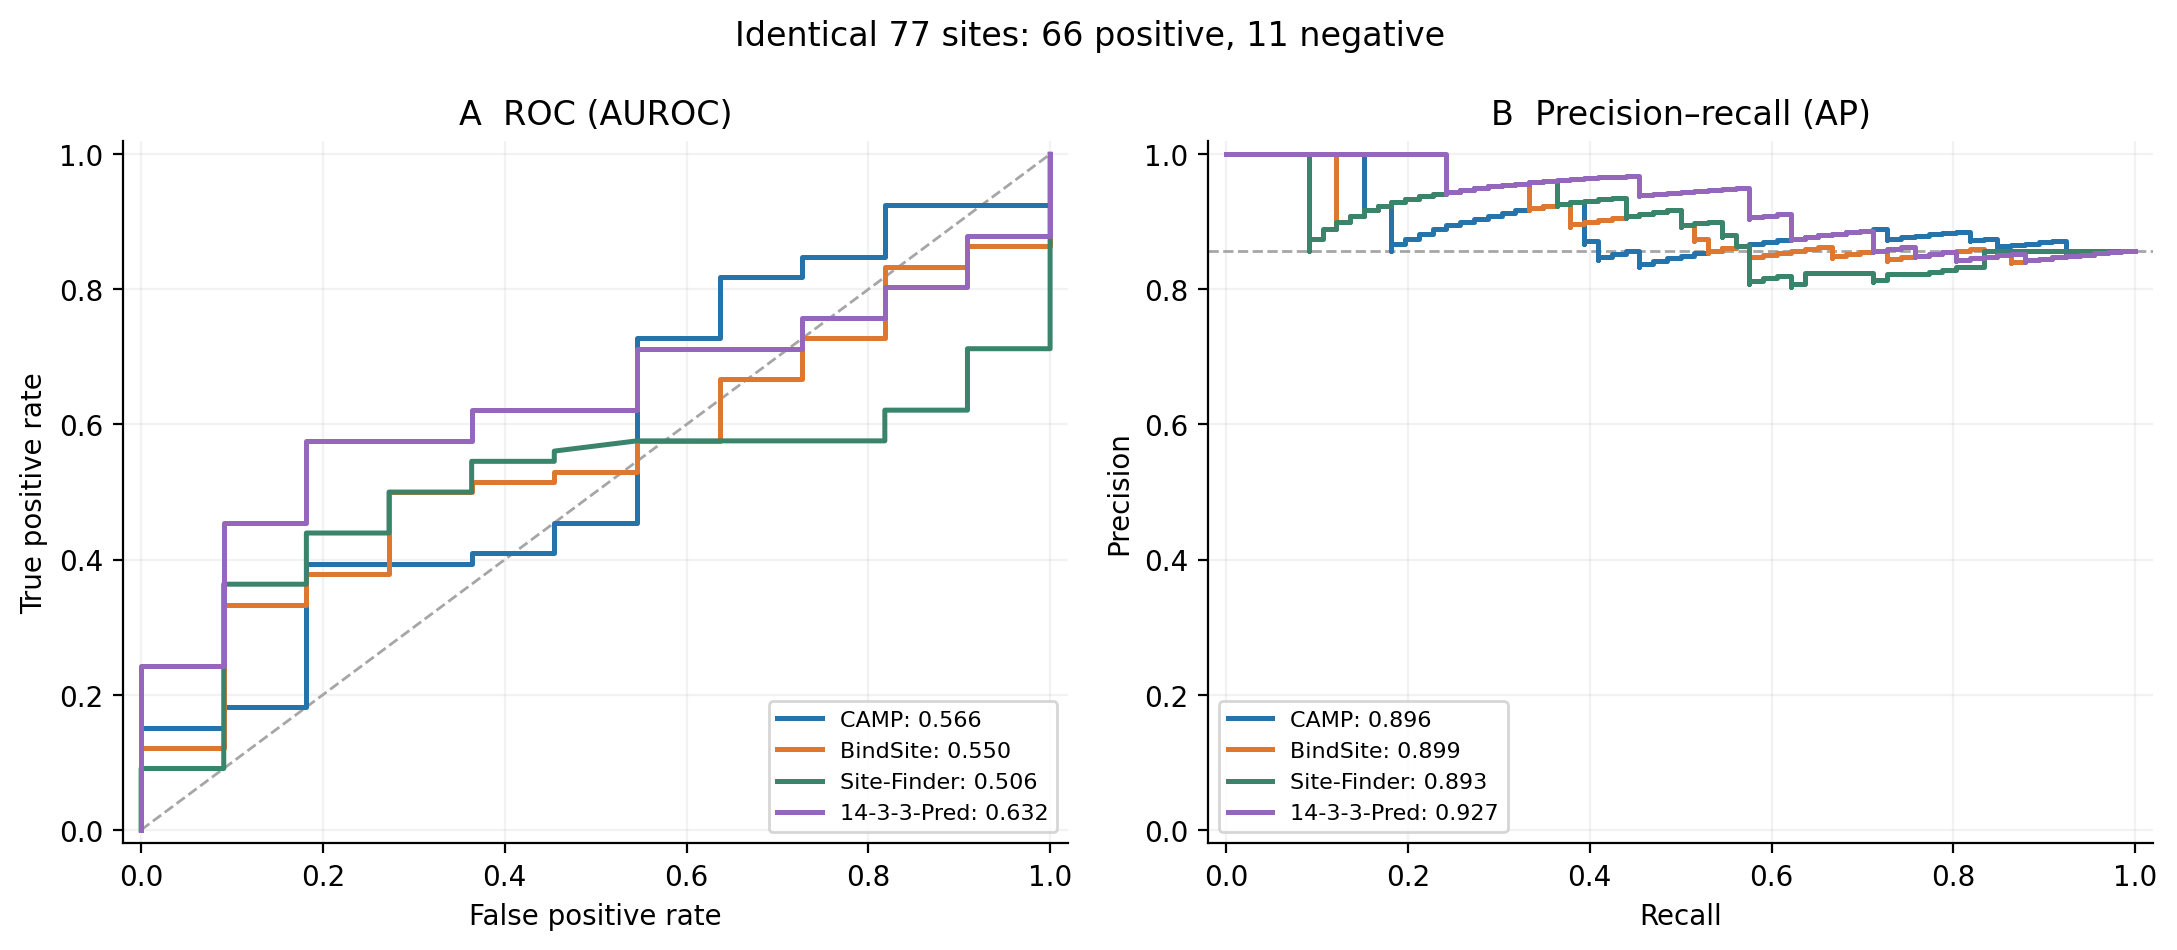

In [4]:
# Figure 5: ROC and precision–recall
fig = plot_benchmark(metrics, roc, pr, "test77", FIGURES)
plt.close(fig)
display(Image(filename=str(FIGURES / "Figure5_benchmark77.png")))


Separate augmented/background diagnostic; not 529 experimental sites.


,cohort,model,AUROC,average_precision,MCC,accuracy,macro_F1
4,full_test529,CAMP,0.896,0.916,0.716,0.851,0.849
5,full_test529,BindSite,0.864,0.885,0.642,0.819,0.818
6,full_test529,Site-Finder,0.852,0.853,0.287,0.578,0.490
7,full_test529,14-3-3-Pred,0.902,0.919,0.675,0.830,0.828


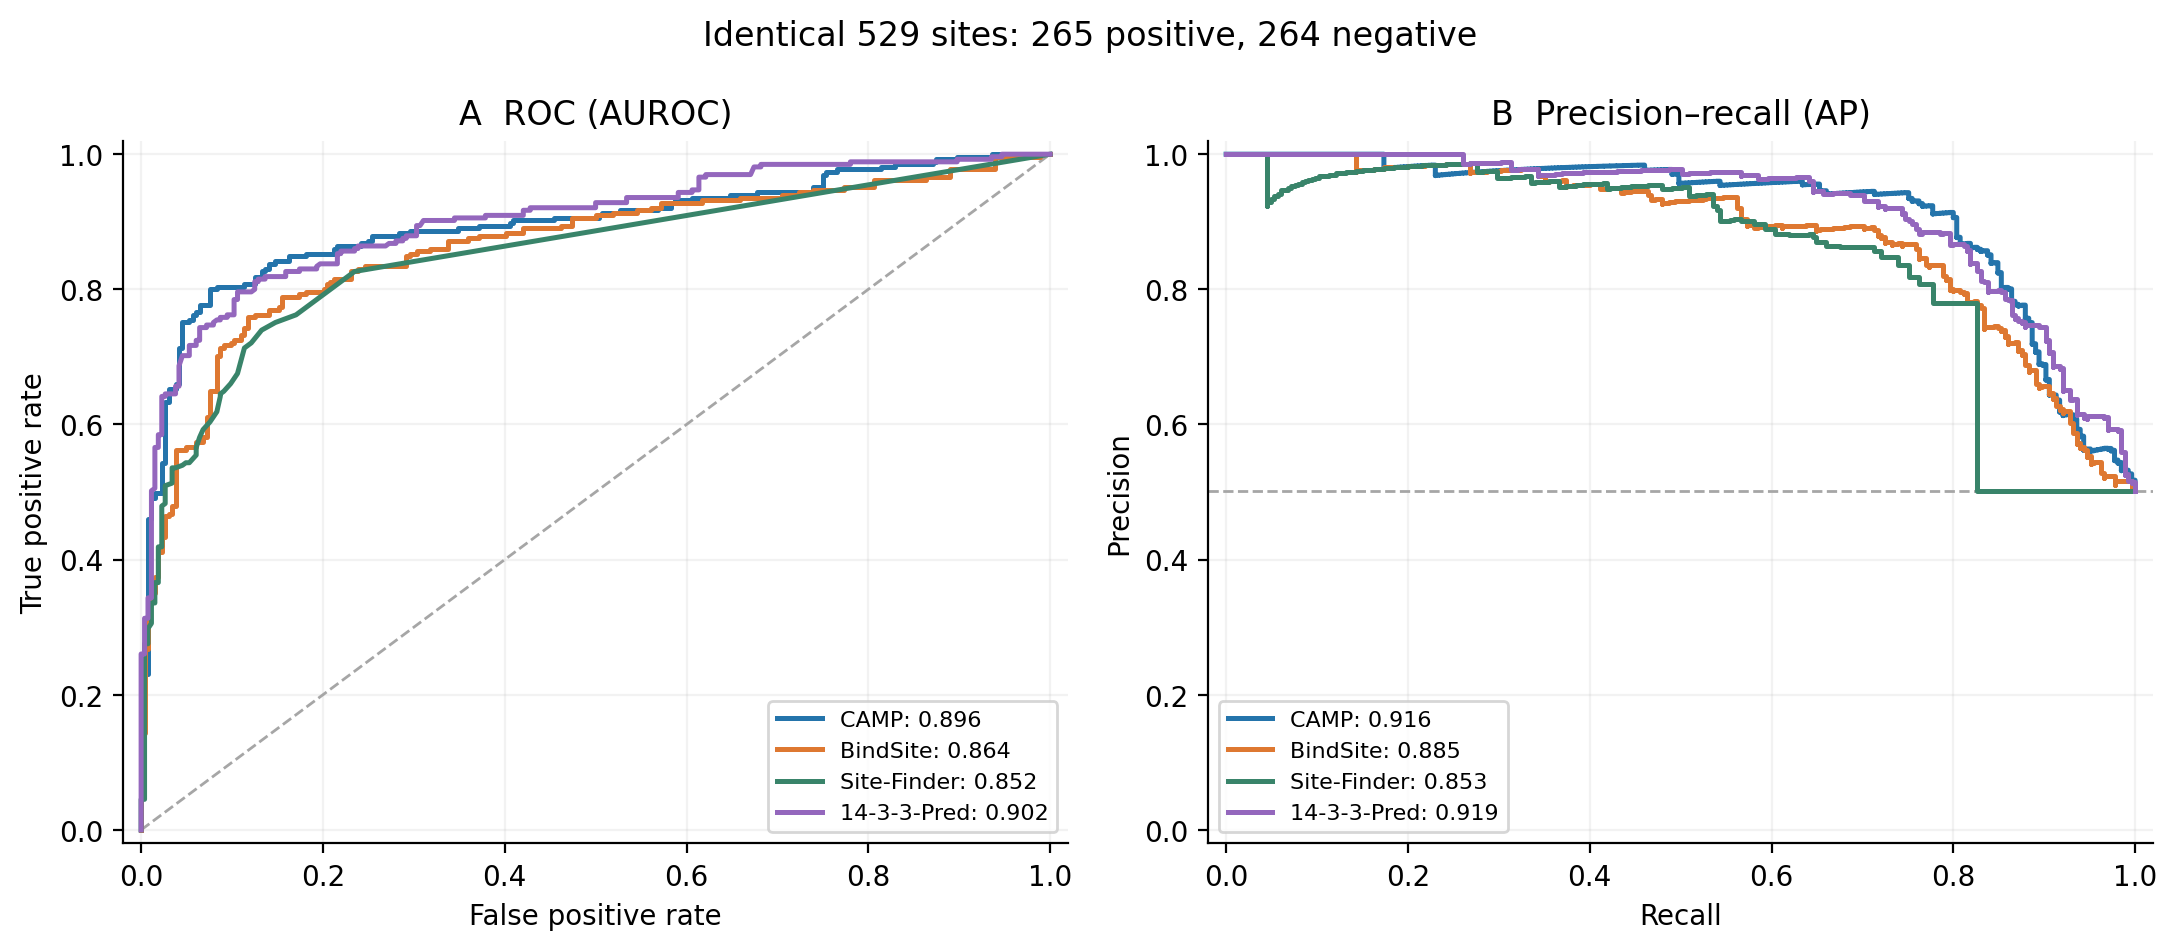

In [5]:
# Supplementary 529-site results
print("Separate augmented/background diagnostic; not 529 experimental sites.")
display(metrics.loc[metrics.cohort == "full_test529", columns].round(3))
plt.close(plot_benchmark(metrics, roc, pr, "full_test529", FIGURES))
display(Image(filename=str(FIGURES / "FigureS_benchmark529.png")))


## 3. Original-score calibration

Five fixed bins on the selected 77 sites. No probability refitting; this does not establish proteome calibration.


,model,n,bins,Brier,ECE,positive_fraction
0,CAMP,77,5,0.2785,0.3134,0.8571


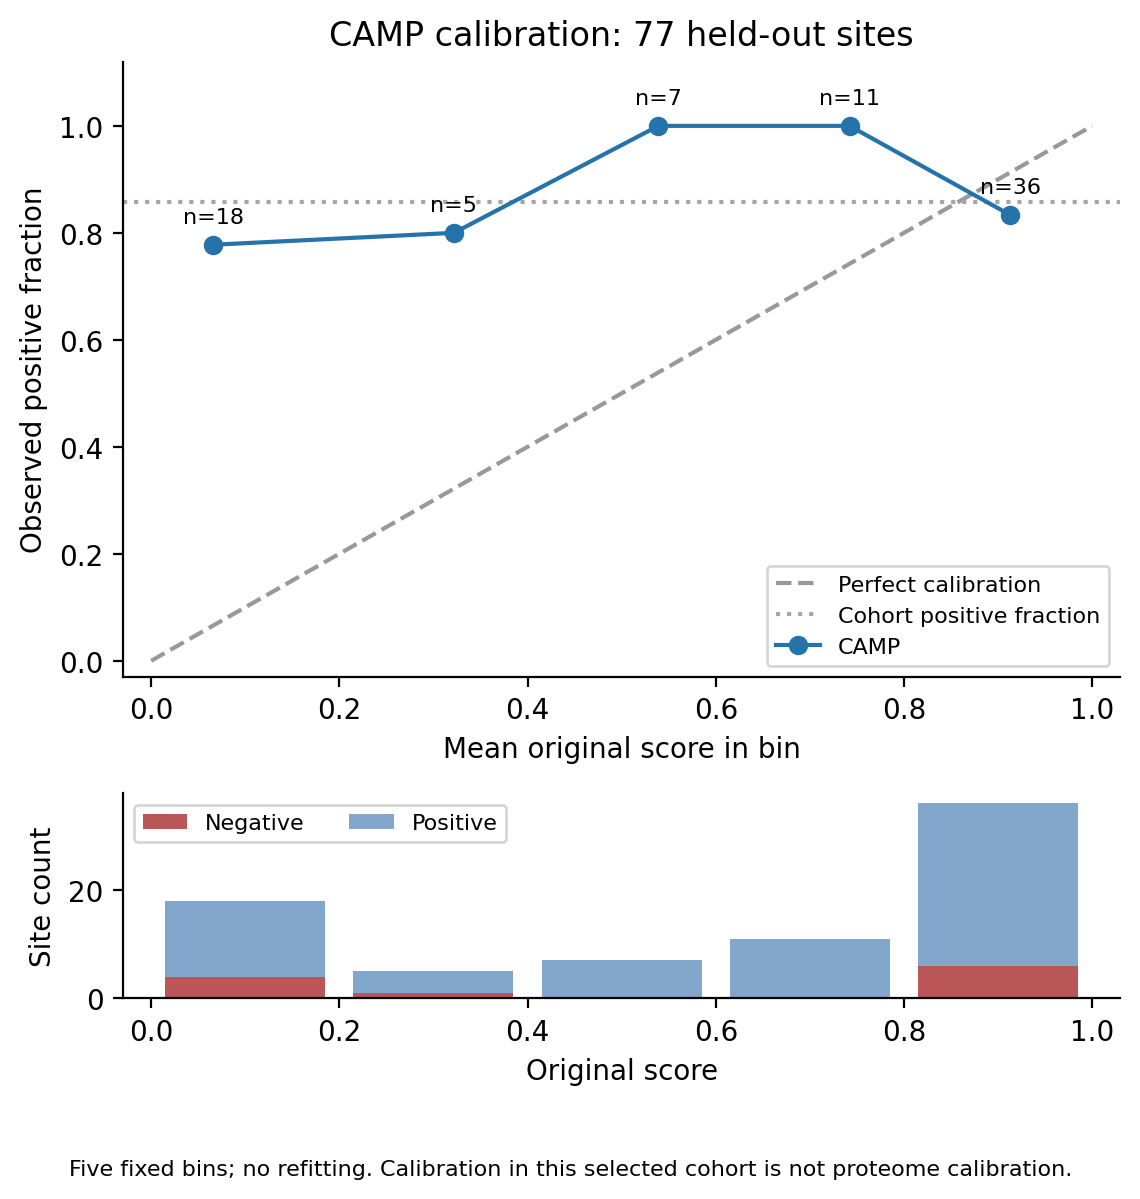

In [6]:
# Figure 6A: CAMP score calibration
bins, diagnostic = calibration(sites)
save_tables(RESULTS, calibration_bins=bins, calibration_summary=diagnostic)
display(diagnostic.round(4))
plt.close(plot_calibration(bins, diagnostic, FIGURES))
display(Image(filename=str(FIGURES / "Figure6A_calibration77.png")))


## 4. Prevalence sensitivity

Hypothetical precision/FDR at fixed class-conditional rates, with 5,000 whole-protein bootstrap draws. These are not measured proteome false discovery rates. The shared cutoff is exploratory for Site-Finder and 14-3-3-Pred.


,model,precision_estimate,FDR_estimate,precision_low,precision_high
2,CAMP,0.0127,0.9873,0.0086,0.0351
6,BindSite,0.0096,0.9904,0.0067,0.0186
10,Site-Finder,0.0262,0.9738,0.0051,1.0000
14,14-3-3-Pred,0.0122,0.9878,0.0072,0.0241


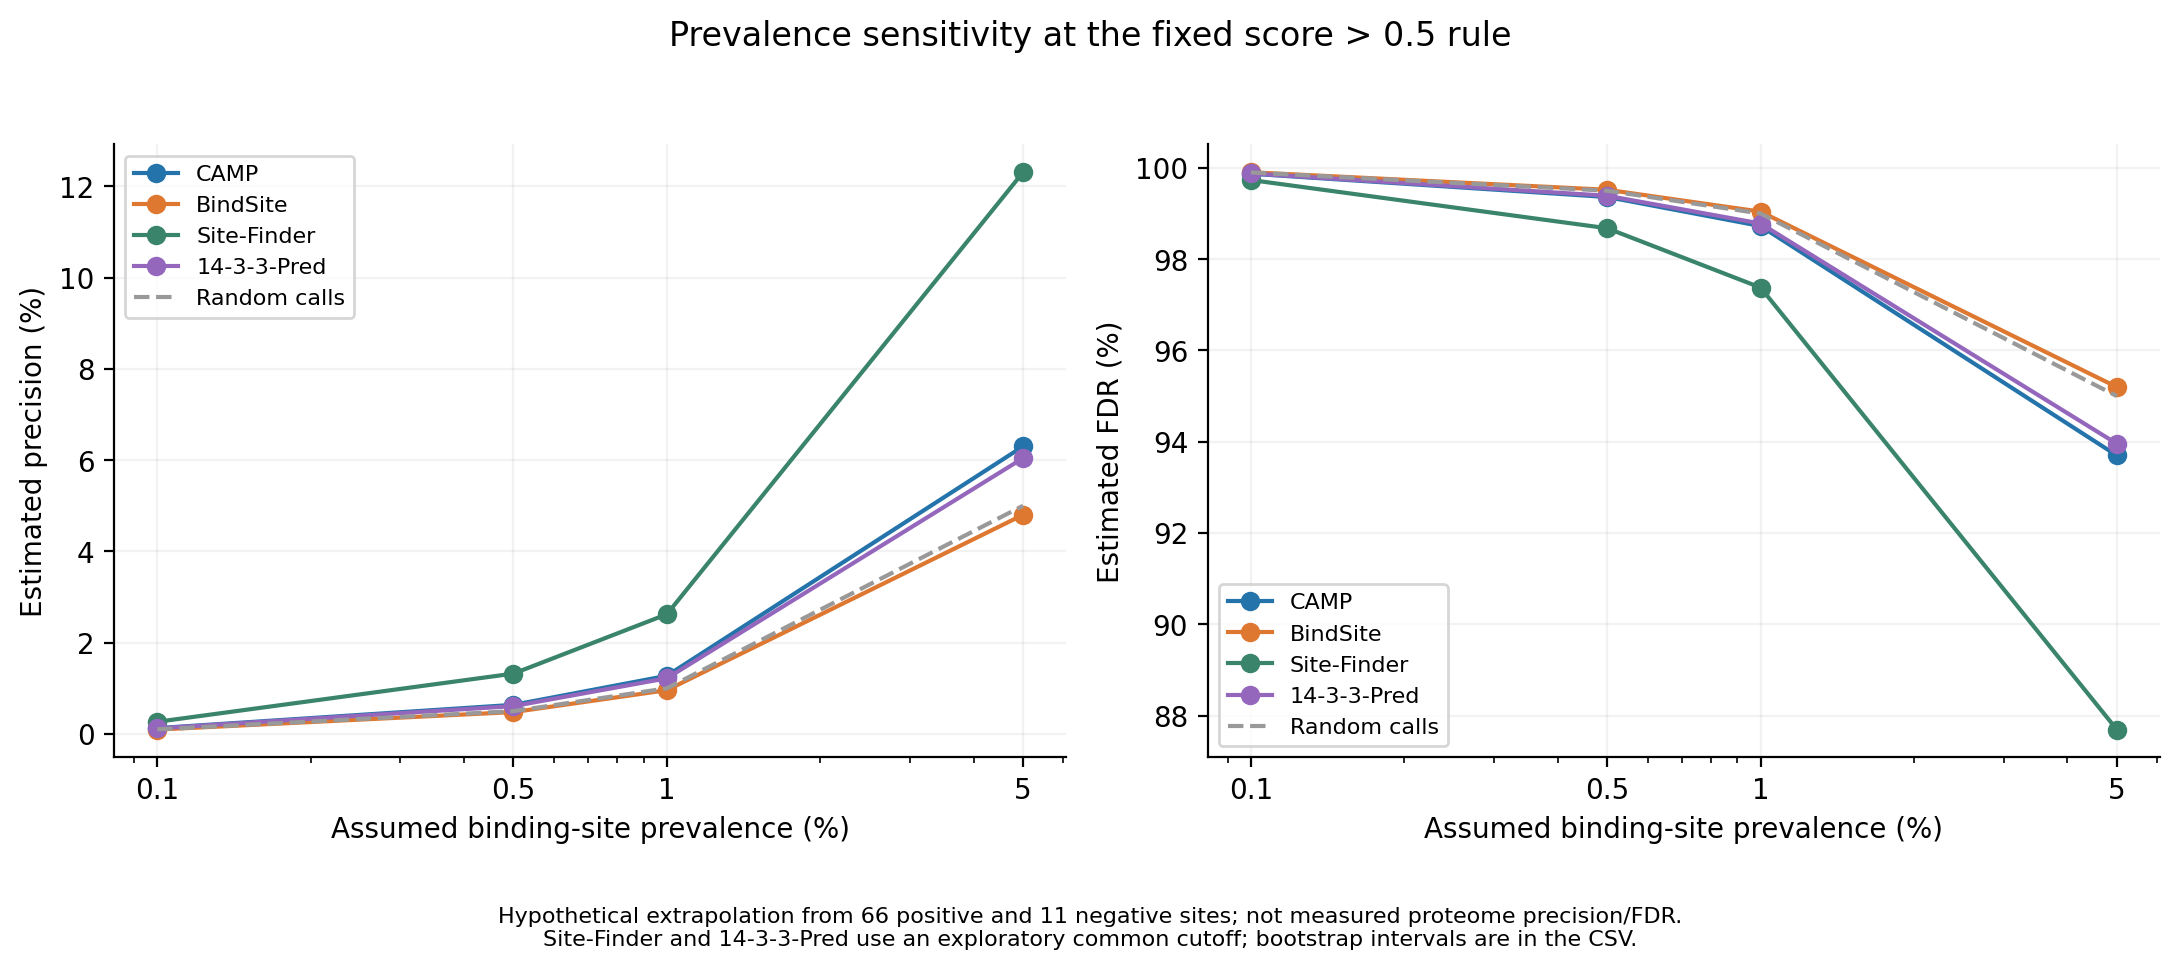

In [7]:
# Figure 6B: precision and FDR under assumed prevalences
estimates, rates, adjusted = prevalence_analysis(sites)
save_tables(RESULTS, precision_fdr=estimates, conditional_rates=rates, adjusted_pr=adjusted)
display(estimates.loc[estimates.assumed_positive_fraction == .01,
                      ["model", "precision_estimate", "FDR_estimate", "precision_low", "precision_high"]].round(4))
plt.close(plot_prevalence(estimates, FIGURES))
display(Image(filename=str(FIGURES / "Figure6B_precision_FDR.png")))


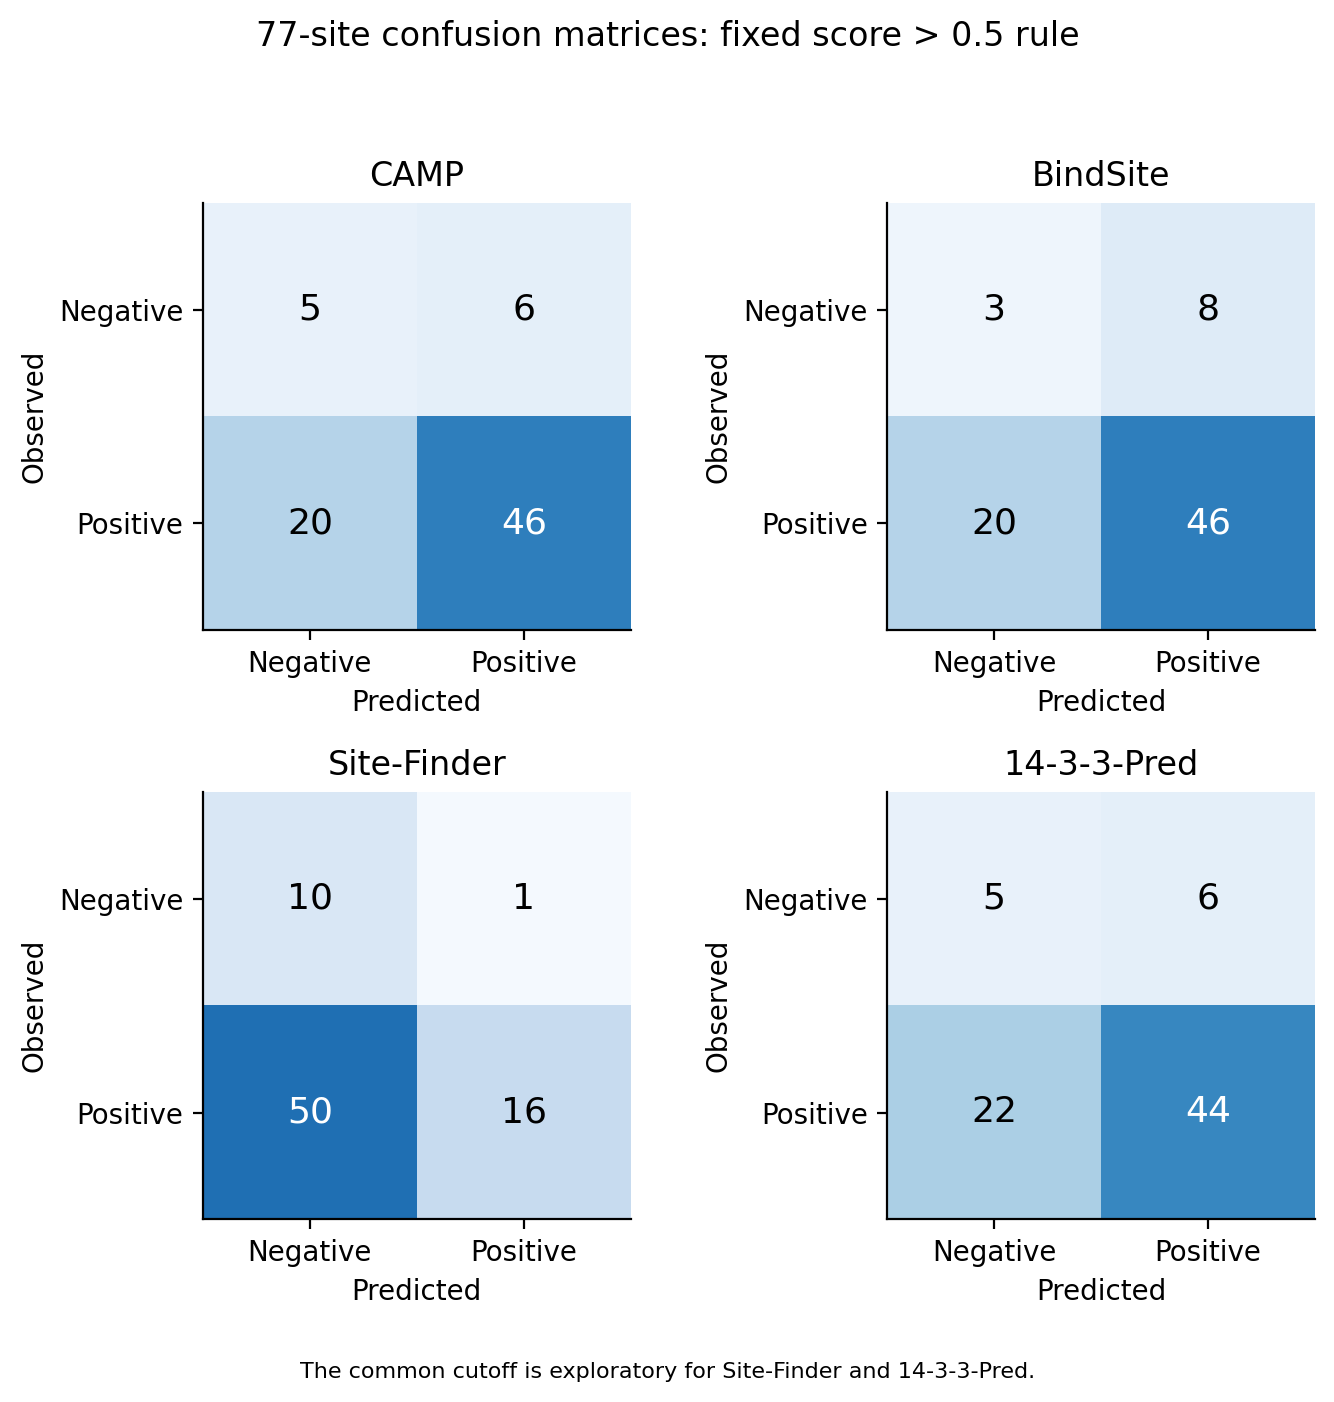

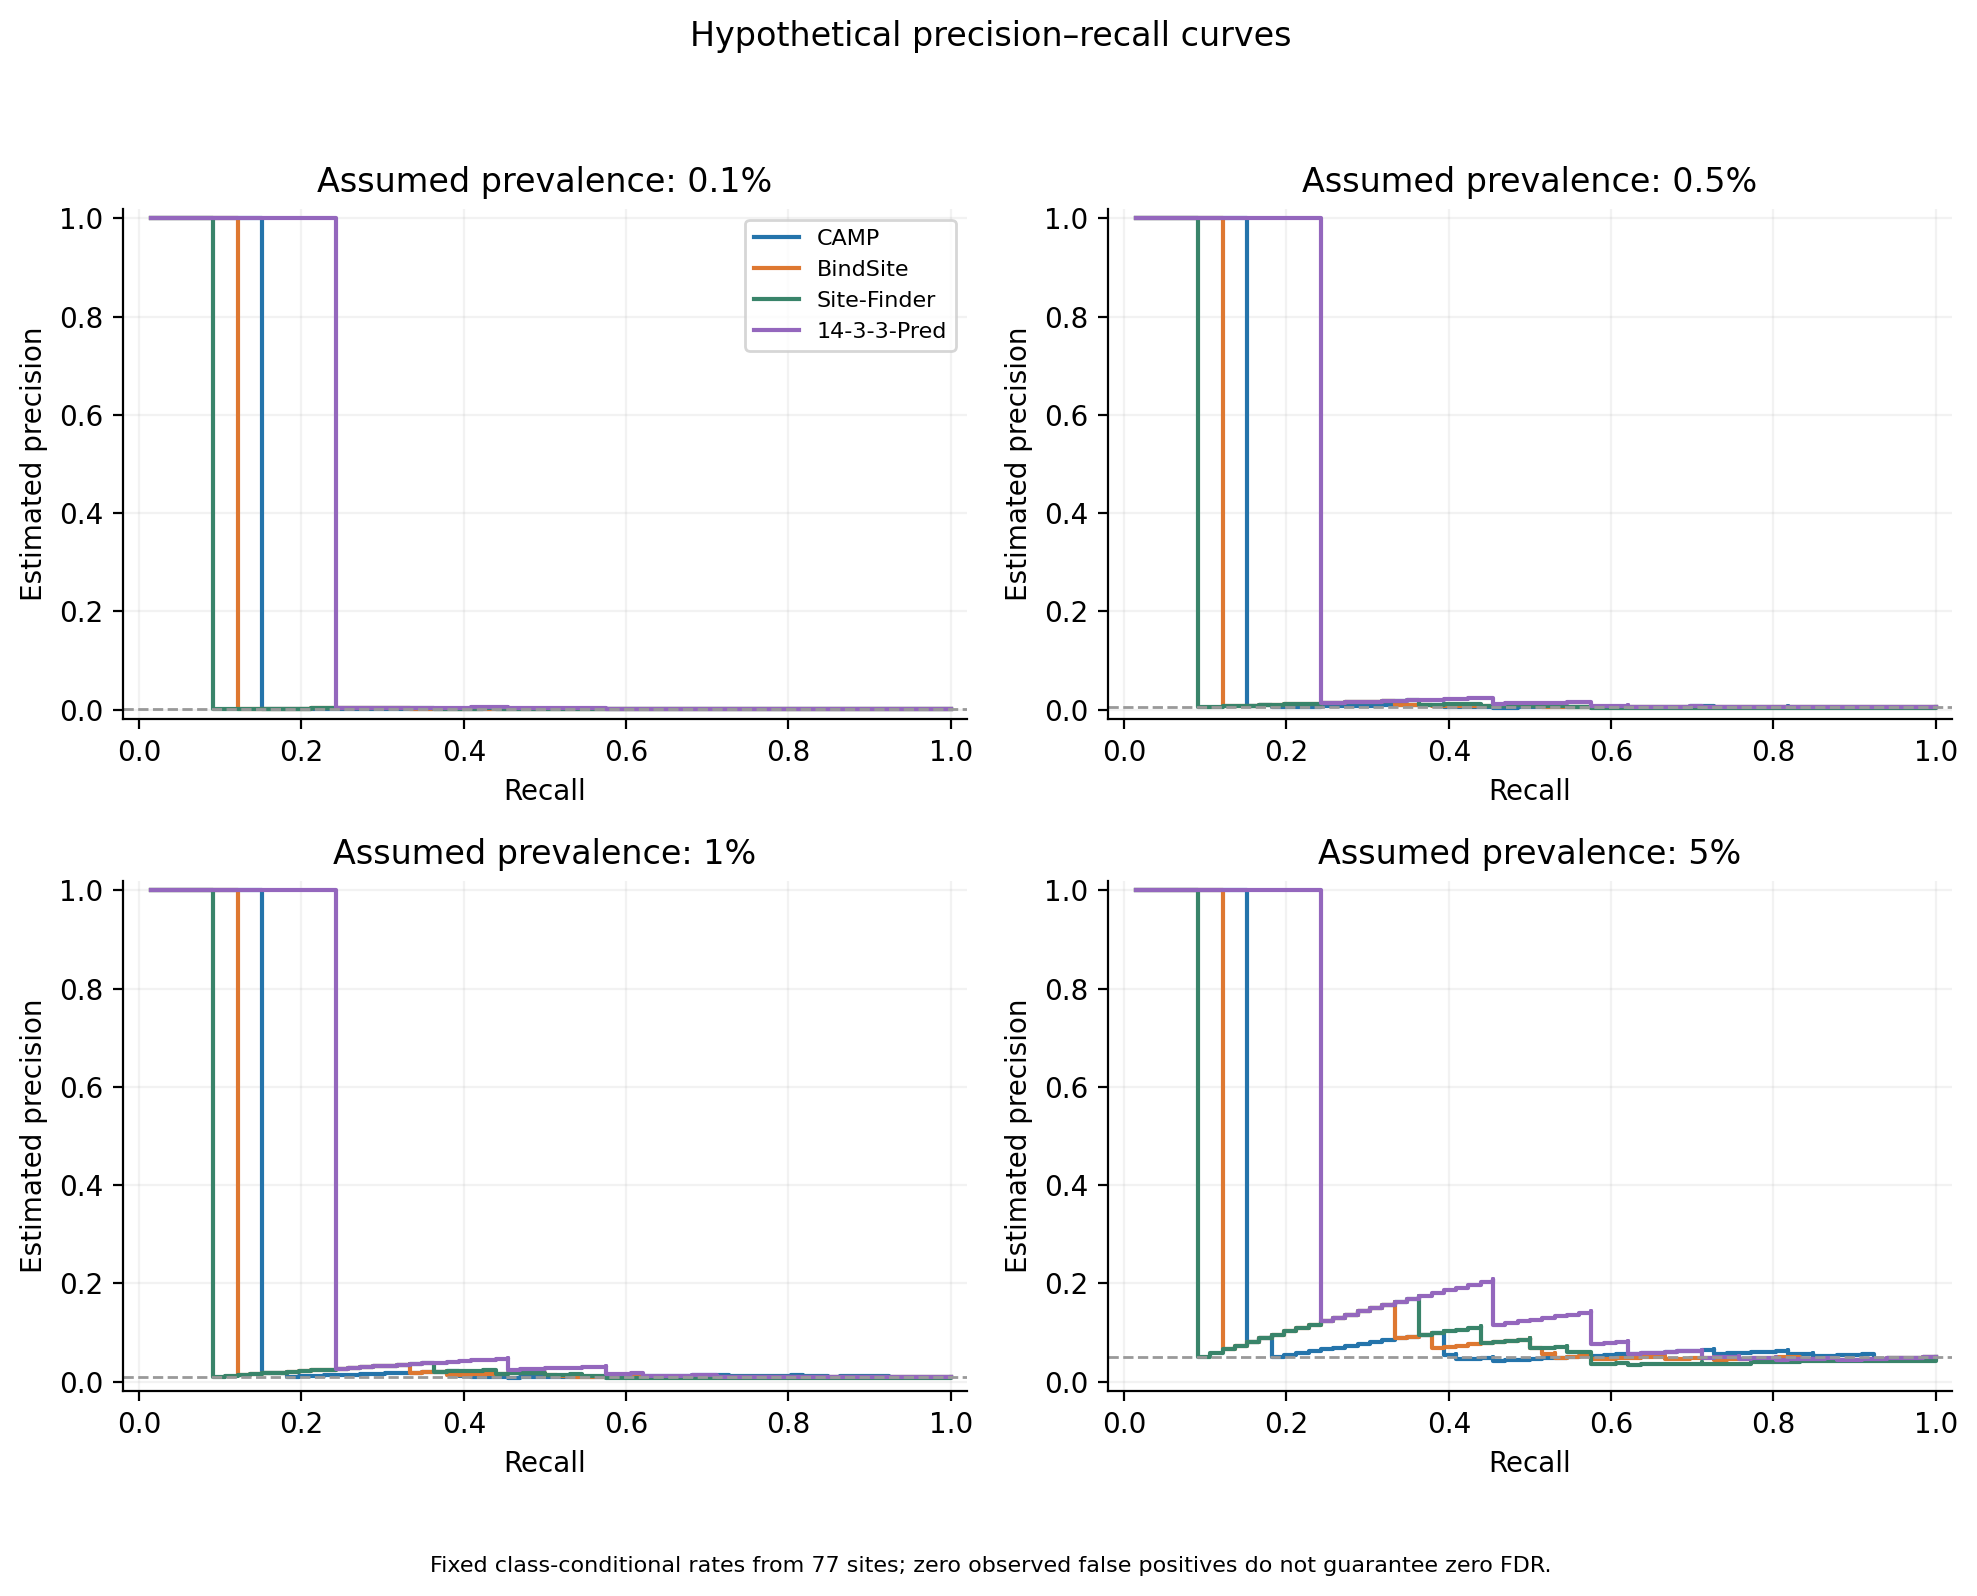

In [8]:
# Supplementary confusion matrices and prevalence-adjusted PR
plt.close(plot_confusion(metrics, FIGURES))
display(Image(filename=str(FIGURES / "FigureS_confusion77.png")))
plt.close(plot_adjusted_pr(adjusted, FIGURES))
display(Image(filename=str(FIGURES / "FigureS_adjusted_PR.png")))


## 5. Label and historical-table corrections

Neighboring D/E mutant contexts retain the original labels. The historical Table 2/4 outputs refer to 459/527 sites and are separate from the new 77/529 comparisons.


In [9]:
# Inspect the three retained D/E contexts and original notebook metrics
display(pd.read_csv(DATA / "label_contexts.csv")[["gene", "target_site", "mutation", "label", "primary_finding", "primary_source"]])
display(pd.read_csv(DATA / "historical_metrics.csv")[["source_cell", "scope", "n", "accuracy_reported", "MCC_reported", "F1_macro_reported"]])


,gene,target_site,mutation,label,primary_finding,primary_source
0,FOXO1,24,S22E,0,S22E reduces 14-3-3 association; T24 phosphory...,https://pmc.ncbi.nlm.nih.gov/articles/PMC6721940/
1,MDM4/HDMX,367,T365D,0,T365D eliminates detectable 14-3-3 co-immunopr...,https://pmc.ncbi.nlm.nih.gov/articles/PMC1592859/
2,YAP1,127,S128D,0,S128D abolishes association at the S127-contai...,https://pmc.ncbi.nlm.nih.gov/articles/PMC5210094/


,source_cell,scope,n,accuracy_reported,MCC_reported,F1_macro_reported
0,103,development_validation,459,0.86,0.713,0.86
1,129,original_independent_test,527,0.84,0.710,0.84
